# Statistical Business Analysis — Week 7

## Project Overview
This project applies introductory statistical methods to business sales data. It covers descriptive statistics, distribution analysis, correlation, hypothesis testing, confidence intervals, and linear regression.

### Objectives
- Calculate descriptive statistics.
- Examine the distribution of sales.
- Measure relationships among business metrics.
- Perform at least three hypothesis tests.
- Calculate a 95% confidence interval and margin of error.
- Build a linear regression model and evaluate R-squared.
- Translate statistical results into practical business insights.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("business_data.csv")
df.head()


,Date,Region,Sales,Marketing_Spend,Customers
0,2026-01-01,South,55732.21,6630.57,221
1,2026-01-02,West,52995.41,6051.49,285
2,2026-01-03,West,52832.72,6637.64,208
3,2026-01-04,South,49103.40,3518.65,342
4,2026-01-05,North,57347.84,6170.49,248


In [2]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Shape: (100, 5)

Data types:
Date                   str
Region                 str
Sales              float64
Marketing_Spend    float64
Customers            int64
dtype: object

Missing values:
Date               0
Region             0
Sales              0
Marketing_Spend    0
Customers          0
dtype: int64

Duplicate rows: 0


## 1. Descriptive Statistics

In [3]:
numeric_cols = ["Sales", "Marketing_Spend", "Customers"]

descriptive = df[numeric_cols].describe().T
descriptive["mode"] = [df[c].mode().iloc[0] for c in numeric_cols]
descriptive["variance"] = [df[c].var() for c in numeric_cols]
descriptive.round(2)


,count,mean,std,min,25%,50%,75%,max,mode,variance
Sales,100.0,55257.63,6987.85,39160.45,50608.12,54891.64,59934.48,74804.67,39160.45,48830041.94
Marketing_Spend,100.0,6496.43,1364.21,3518.65,5442.31,6616.70,7225.54,10000.00,3518.65,1861067.95
Customers,100.0,221.47,47.22,100.00,186.50,223.00,251.00,350.00,243.00,2229.79


## 2. Distribution Analysis

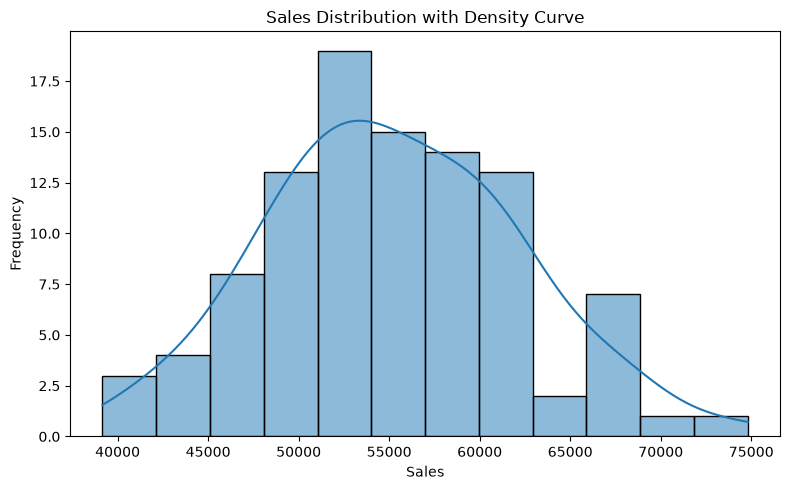

,Shapiro statistic,p-value
Sales,0.9932,0.9013
Marketing_Spend,0.9884,0.5405
Customers,0.9906,0.7163


In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Sales"], kde=True, bins=12)
plt.title("Sales Distribution with Density Curve")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

normality_results = {}
for col in numeric_cols:
    statistic, p_value = stats.shapiro(df[col])
    normality_results[col] = {"Shapiro statistic": statistic, "p-value": p_value}

pd.DataFrame(normality_results).T.round(4)


## 3. Correlation Analysis

,Sales,Marketing_Spend,Customers
Sales,1.000,0.805,0.376
Marketing_Spend,0.805,1.000,-0.016
Customers,0.376,-0.016,1.000


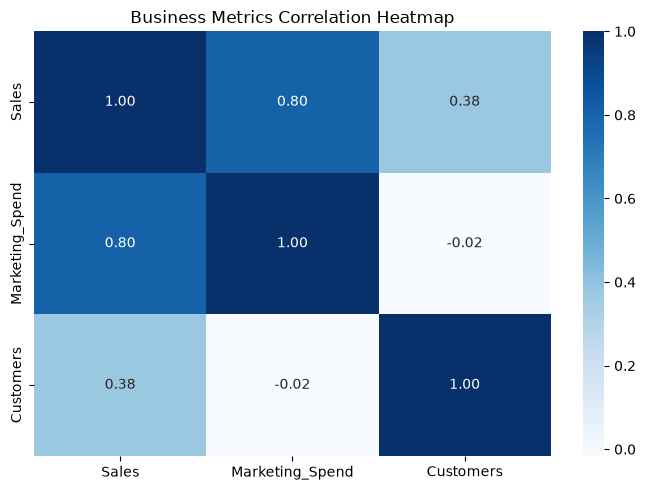

In [5]:
correlation = df[numeric_cols].corr()
display(correlation.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="Blues")
plt.title("Business Metrics Correlation Heatmap")
plt.tight_layout()
plt.show()


## 4. Hypothesis Testing

In [6]:
# Test 1: one-sample t-test against a $45,000 benchmark
benchmark = 45000
t1, p1 = stats.ttest_1samp(df["Sales"], benchmark)

# Test 2: North vs South independent t-test
north = df.loc[df["Region"] == "North", "Sales"]
south = df.loc[df["Region"] == "South", "Sales"]
t2, p2 = stats.ttest_ind(north, south, equal_var=False)

# Test 3: one-way ANOVA across regions
groups = [df.loc[df["Region"] == r, "Sales"] for r in ["North", "South", "West"]]
f3, p3 = stats.f_oneway(*groups)

hypothesis_results = pd.DataFrame([
    ["One-sample t-test", t1, p1, "Significant" if p1 < 0.05 else "Not significant"],
    ["North vs South t-test", t2, p2, "Significant" if p2 < 0.05 else "Not significant"],
    ["Regional ANOVA", f3, p3, "Significant" if p3 < 0.05 else "Not significant"],
], columns=["Test", "Statistic", "p-value", "Decision"])

hypothesis_results


,Test,Statistic,p-value,Decision
0,One-sample t-test,14.679235,1.368537e-26,Significant
1,North vs South t-test,3.642218,5.687768e-04,Significant
2,Regional ANOVA,8.553183,3.792279e-04,Significant


## 5. Confidence Interval

In [7]:
mean_sales = df["Sales"].mean()
sem_sales = stats.sem(df["Sales"])
ci_low, ci_high = stats.t.interval(0.95, len(df)-1, loc=mean_sales, scale=sem_sales)
margin_of_error = mean_sales - ci_low

print(f"Mean Sales: ${mean_sales:,.2f}")
print(f"95% CI: ${ci_low:,.2f} to ${ci_high:,.2f}")
print(f"Margin of Error: ±${margin_of_error:,.2f}")


Mean Sales: $55,257.63
95% CI: $53,871.09 to $56,644.17
Margin of Error: ±$1,386.54


## 6. Linear Regression

Intercept: 28,482.99
Marketing coefficient: 4.1214
R-squared: 0.6474
RMSE: 4,128.59


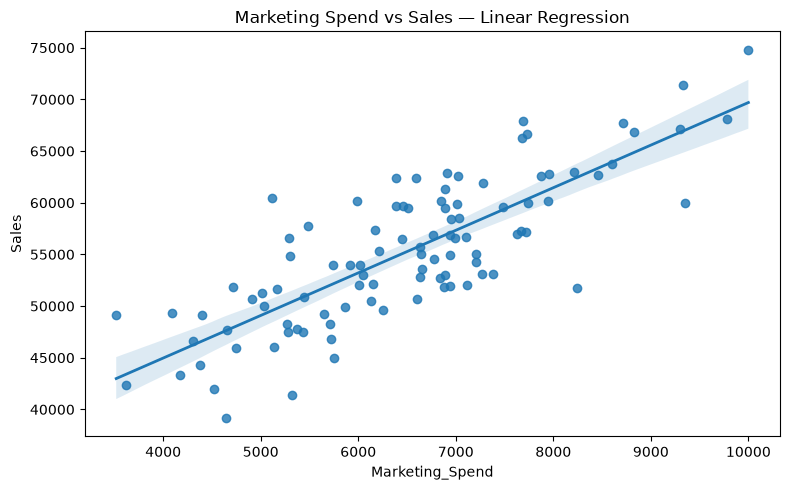

In [8]:
X = df[["Marketing_Spend"]]
y = df["Sales"]

model = LinearRegression()
model.fit(X, y)

predictions = model.predict(X)
r2 = r2_score(y, predictions)
rmse = mean_squared_error(y, predictions) ** 0.5

print(f"Intercept: {model.intercept_:,.2f}")
print(f"Marketing coefficient: {model.coef_[0]:.4f}")
print(f"R-squared: {r2:.4f}")
print(f"RMSE: {rmse:,.2f}")

plt.figure(figsize=(8, 5))
sns.regplot(x="Marketing_Spend", y="Sales", data=df, line_kws={"linewidth": 2})
plt.title("Marketing Spend vs Sales — Linear Regression")
plt.tight_layout()
plt.show()


## 7. Business Insights & Recommendations

1. Use the correlation result to understand how strongly marketing spend is associated with sales.
2. Use hypothesis-test p-values rather than averages alone when deciding whether observed differences are statistically meaningful.
3. Regional differences identified by the t-test/ANOVA can guide region-specific sales strategies.
4. The 95% confidence interval provides a reasonable range for the population mean daily sales.
5. R-squared indicates how much variation in sales is explained by marketing spend in the simple regression model.

### Conclusion
The analysis demonstrates the complete introductory statistics workflow required for the Week 7 internship task: descriptive statistics, distribution analysis, correlation, three hypothesis tests, confidence intervals, and regression.
